# 6. Búsqueda de vecindad variable

La búsqueda de vecindad variable (*variable neighborhood search*, VNS) parte de una observación sobre los óptimos locales. Un óptimo local lo es con respecto a un vecindario, y con otro vecindario puede ser una solución mejorable. El capítulo presenta primero el descenso por vecindad variable (VND), que recorre varios vecindarios en un orden fijo, y después la VNS, que alterna una agitación de la solución con una búsqueda local o con un VND. Los ejemplos son la mochila, incluida la de 100 objetos en la que la búsqueda tabú y la búsqueda local iterada no llegaron al óptimo en el capítulo 5, y el agente viajero.

In [1]:
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt

## Instancias y código común

El capítulo usa la mochila de 100 objetos y el agente viajero de 50 ciudades del capítulo 5. La celda oculta repite las clases de los dos problemas, el presupuesto, la búsqueda local, ILS y la búsqueda tabú de los capítulos 4 y 5.

In [2]:
np.random.seed(42)
random.seed(42)

# Mismas instancias de los capítulos 1, 3 y 4
N_OBJETOS = 20
pesos20 = np.random.randint(1, 31, size=N_OBJETOS)
valores20 = np.random.randint(1, 51, size=N_OBJETOS)
capacidad20 = int(0.4 * pesos20.sum())

N_CIUDADES = 50
ciudades = np.random.uniform(0, 100, size=(N_CIUDADES, 2))
distancias = np.sqrt(((ciudades[:, None, :] - ciudades[None, :, :]) ** 2).sum(axis=2))

# Mochila de 100 objetos con valores correlacionados con los pesos
rng = np.random.default_rng(2026)
pesos100 = rng.integers(1, 101, size=100)
valores100 = pesos100 + 10
capacidad100 = int(0.5 * pesos100.sum())


def optimo_mochila_pd(pesos, valores, capacidad):
    """Valor óptimo de la mochila 0-1 por programación dinámica sobre la capacidad."""
    mejor = np.zeros(capacidad + 1, dtype=np.int64)
    for w, v in zip(pesos, valores):
        mejor[w:] = np.maximum(mejor[w:], mejor[:-w] + v) if w > 0 else mejor[w:]
    return int(mejor[capacidad])


OPTIMO_MOCHILA100 = optimo_mochila_pd(pesos100, valores100, capacidad100)
print(f"Mochila de 100 objetos: peso total {pesos100.sum()}, capacidad {capacidad100}, "
      f"valor óptimo por programación dinámica {OPTIMO_MOCHILA100}")
print(f"Comprobación con la mochila de 20 objetos: {optimo_mochila_pd(pesos20, valores20, capacidad20)} (capítulo 1: 402)")

Mochila de 100 objetos: peso total 5028, capacidad 2514, valor óptimo por programación dinámica 3204
Comprobación con la mochila de 20 objetos: 402 (capítulo 1: 402)


In [3]:
class Mochila:
    """Mochila 0-1. Costo: valor con signo cambiado. Movimientos: flip e intercambio."""

    def __init__(self, pesos, valores, capacidad):
        self.pesos, self.valores, self.capacidad = pesos, valores, capacidad
        self.n = len(pesos)

    def aleatoria(self):
        x = np.zeros(self.n, dtype=int)
        peso = 0
        for i in np.random.permutation(self.n):
            if np.random.random() < 0.5 and peso + self.pesos[i] <= self.capacidad:
                x[i] = 1
                peso += self.pesos[i]
        return x

    def costo(self, x):
        return -int(np.dot(x, self.valores))

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [('flip', i) for i in range(self.n)] + [('swap', i, j) for i in dentro for j in fuera]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        r = random.randrange(self.n + len(dentro) * len(fuera))
        if r < self.n:
            return ('flip', r)
        r -= self.n
        return ('swap', dentro[r // len(fuera)], fuera[r % len(fuera)])

    def delta(self, x, mov):
        peso = np.dot(x, self.pesos)
        if mov[0] == 'flip':
            i = mov[1]
            signo = 1 if x[i] == 0 else -1
            if peso + signo * self.pesos[i] > self.capacidad:
                return None
            return -signo * self.valores[i]
        _, i, j = mov
        if peso - self.pesos[i] + self.pesos[j] > self.capacidad:
            return None
        return self.valores[i] - self.valores[j]

    def aplicar(self, x, mov):
        y = x.copy()
        if mov[0] == 'flip':
            y[mov[1]] = 1 - y[mov[1]]
        else:
            y[mov[1]], y[mov[2]] = 0, 1
        return y

    def perturbar(self, x, k=3):
        y = x.copy()
        for i in np.random.choice(self.n, size=k, replace=False):
            y[i] = 1 - y[i]
        while np.dot(y, self.pesos) > self.capacidad:
            y[np.random.choice(np.flatnonzero(y == 1))] = 0
        return y

    def construir_grasp(self, alfa):
        x = np.zeros(self.n, dtype=int)
        peso = 0
        while True:
            candidatos = [i for i in range(self.n) if x[i] == 0 and peso + self.pesos[i] <= self.capacidad]
            if not candidatos:
                return x
            razon = {i: self.valores[i] / self.pesos[i] for i in candidatos}
            r_max, r_min = max(razon.values()), min(razon.values())
            lrc = [i for i in candidatos if razon[i] >= r_max - alfa * (r_max - r_min)]
            i = random.choice(lrc)
            x[i] = 1
            peso += self.pesos[i]

    # Atributos tabú: los objetos que cambian de estado
    def atributos(self, x, mov):
        return {mov[1]} if mov[0] == 'flip' else {mov[1], mov[2]}

    def es_tabu(self, x, mov, tabu_hasta, iteracion):
        return any(tabu_hasta.get(a, 0) > iteracion for a in self.atributos(x, mov))



class Viajero:
    """Agente viajero. Costo: longitud del recorrido. Movimiento: 2-opt."""

    def __init__(self, distancias):
        self.d = distancias
        self.n = len(distancias)

    def aleatoria(self):
        return list(np.random.permutation(self.n))

    def costo(self, ruta):
        return sum(self.d[ruta[k], ruta[(k + 1) % self.n]] for k in range(self.n))

    def movimientos(self, ruta):
        movs = [(i, j) for i in range(self.n - 1) for j in range(i + 2, self.n) if not (i == 0 and j == self.n - 1)]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, ruta):
        while True:
            i, j = sorted(random.sample(range(self.n), 2))
            if j >= i + 2 and not (i == 0 and j == self.n - 1):
                return (i, j)

    def delta(self, ruta, mov):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        return self.d[a, c] + self.d[b, d] - self.d[a, b] - self.d[c, d]

    def aplicar(self, ruta, mov):
        i, j = mov
        return ruta[:i + 1] + ruta[i + 1:j + 1][::-1] + ruta[j + 1:]

    def perturbar(self, ruta, k=None):
        p1, p2, p3 = sorted(random.sample(range(1, self.n), 3))
        return ruta[:p1] + ruta[p2:p3] + ruta[p1:p2] + ruta[p3:]

    def construir_grasp(self, alfa):
        ruta = [random.randrange(self.n)]
        pendientes = set(range(self.n)) - {ruta[0]}
        while pendientes:
            dist = {j: self.d[ruta[-1], j] for j in pendientes}
            d_min, d_max = min(dist.values()), max(dist.values())
            lrc = [j for j in pendientes if dist[j] <= d_min + alfa * (d_max - d_min)]
            j = random.choice(lrc)
            ruta.append(j)
            pendientes.remove(j)
        return ruta

    # Atributos tabú: los arcos que el movimiento quita (no se pueden volver a poner)
    def atributos(self, ruta, mov):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        return {frozenset((a, b)), frozenset((c, d))}

    def es_tabu(self, ruta, mov, tabu_hasta, iteracion):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        agregados = (frozenset((a, c)), frozenset((b, d)))
        return any(tabu_hasta.get(arco, 0) > iteracion for arco in agregados)


class Presupuesto:
    """Cuenta las evaluaciones de vecinos y avisa cuando se agotan."""

    def __init__(self, maximo):
        self.maximo, self.usadas = maximo, 0

    def gastar(self, k=1):
        self.usadas += k

    @property
    def agotado(self):
        return self.usadas >= self.maximo


def busqueda_local(prob, x, presupuesto):
    """Primera mejora, como en el capítulo 4."""
    c = prob.costo(x)
    while not presupuesto.agotado:
        mejoro = False
        for mov in prob.movimientos(x):
            if presupuesto.agotado:
                break
            d = prob.delta(x, mov)
            presupuesto.gastar()
            if d is not None and d < -1e-9:
                x, c = prob.aplicar(x, mov), c + d
                mejoro = True
                break
        if not mejoro:
            break
    return x, c


def busqueda_local_iterada(prob, presupuesto):
    """ILS del capítulo 4."""
    x, c = busqueda_local(prob, prob.aleatoria(), presupuesto)
    mejor_x, mejor_c = x, c
    while not presupuesto.agotado:
        y, cy = busqueda_local(prob, prob.perturbar(x), presupuesto)
        if cy <= c:
            x, c = y, cy
            if c < mejor_c:
                mejor_x, mejor_c = x, c
    return mejor_x, mejor_c



def busqueda_tabu(prob, presupuesto, permanencia, muestra=None, x0=None):
    """
    En cada iteración evalúa los vecinos de la solución actual (todos, o una muestra
    aleatoria de tamaño muestra) y se mueve al mejor que no sea tabú, aunque empeore.
    Un movimiento tabú se admite si produce una solución mejor que la mejor encontrada
    (criterio de aspiración). Los atributos del movimiento aplicado quedan prohibidos
    durante permanencia iteraciones.
    """
    x = prob.aleatoria() if x0 is None else x0
    c = prob.costo(x)
    mejor_x, mejor_c = x, c
    tabu_hasta = {}
    iteracion = 0
    historia = []
    while not presupuesto.agotado:
        iteracion += 1
        if muestra is None:
            candidatos = prob.movimientos(x)
        else:
            candidatos = [prob.movimiento_aleatorio(x) for _ in range(muestra)]
        mejor_mov, mejor_d = None, math.inf
        for mov in candidatos:
            if presupuesto.agotado:
                break
            d = prob.delta(x, mov)
            presupuesto.gastar()
            if d is None:
                continue
            if prob.es_tabu(x, mov, tabu_hasta, iteracion) and not (c + d < mejor_c - 1e-9):
                continue  # Tabú y sin aspiración
            if d < mejor_d:
                mejor_mov, mejor_d = mov, d
        if mejor_mov is None:
            continue
        for a in prob.atributos(x, mejor_mov):
            tabu_hasta[a] = iteracion + permanencia
        x, c = prob.aplicar(x, mejor_mov), c + mejor_d
        if c < mejor_c - 1e-9:
            mejor_x, mejor_c = x, c
        historia.append((c, mejor_c))
    return mejor_x, mejor_c, historia



mochila20 = Mochila(pesos20, valores20, capacidad20)
mochila100 = Mochila(pesos100, valores100, capacidad100)
viajero = Viajero(distancias)

## La idea del método

El método, propuesto por Mladenović y Hansen en 1997, se apoya en tres principios sobre los óptimos locales:

- un óptimo local con respecto a un vecindario no es necesariamente un óptimo local con respecto a otro;
- un óptimo global es óptimo local con respecto a todos los vecindarios;
- con frecuencia, los óptimos locales con respecto a vecindarios parecidos están cerca unos de otros.

El primero dice que cambiar de vecindario permite seguir mejorando cuando la búsqueda local se detiene. El segundo, que una solución que ningún vecindario mejora es mejor candidata a óptimo global que una que solo es óptimo local para uno. El tercero justifica buscar cerca del óptimo local actual, como hace la búsqueda local iterada.

## Vecindarios para la mochila y el agente viajero

VNS necesita varios vecindarios para cada problema, ordenados de modo que los primeros sean los más pequeños y baratos de revisar. Cada vecindario es una clase con los tres métodos de la interfaz del capítulo 4, `movimientos`, `delta` y `aplicar`. En la mochila hay cuatro:

- $N_1$, *flip*, cambia el estado de un objeto, con $n$ vecinos;
- $N_2$, intercambio 1-1, saca un objeto y mete otro, con $k(n-k)$ vecinos si hay $k$ objetos en la mochila;
- $N_3$, intercambio 1-2, saca un objeto y mete dos, con $k\binom{n-k}{2}$ vecinos;
- $N_4$, intercambio 2-2, saca dos objetos y mete otros dos, con $\binom{k}{2}\binom{n-k}{2}$ vecinos.

$N_4$ solo se usa en la instancia pequeña, porque en la mochila de 100 objetos, con unos 50 objetos dentro, tiene más de un millón de vecinos. En el agente viajero hay dos:

- $N_1$, 2-opt, con $n(n-3)/2$ vecinos;
- $N_2$, or-opt, que mueve un tramo de 1, 2 o 3 ciudades consecutivas a otra posición del recorrido, sin invertirlo.

Si el tramo de or-opt va de la ciudad $s_0$ a la ciudad $s_L$, estaba entre $a$ y $b$ y se inserta entre $c$ y $e$, el cambio de longitud es

$$\Delta = d_{ab} + d_{c s_0} + d_{s_L e} - d_{a s_0} - d_{s_L b} - d_{ce}.$$

Las diapositivas del curso mencionan también 3-opt, que no se usa aquí. La celda siguiente comprueba los cambios de costo de los vecindarios nuevos contra el cálculo completo y cuenta los movimientos de or-opt.

In [4]:
class Flip:
    """Mochila, N1: cambia el estado de un objeto."""
    nombre = 'flip'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, x):
        movs = list(range(self.p.n))
        random.shuffle(movs)
        return movs

    def delta(self, x, i):
        return self.p.delta(x, ('flip', i))

    def aplicar(self, x, i):
        return self.p.aplicar(x, ('flip', i))


class Intercambio:
    """Mochila, N2: saca un objeto y mete otro."""
    nombre = 'intercambio 1-1'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [(i, j) for i in dentro for j in fuera]
        random.shuffle(movs)
        return movs

    def delta(self, x, mov):
        return self.p.delta(x, ('swap', mov[0], mov[1]))

    def aplicar(self, x, mov):
        return self.p.aplicar(x, ('swap', mov[0], mov[1]))


class Intercambio12:
    """Mochila, N3: saca un objeto y mete dos."""
    nombre = 'intercambio 1-2'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [(i, j, k) for i in dentro for a, j in enumerate(fuera) for k in fuera[a + 1:]]
        random.shuffle(movs)
        return movs

    def delta(self, x, mov):
        i, j, k = mov
        p = self.p
        if np.dot(x, p.pesos) - p.pesos[i] + p.pesos[j] + p.pesos[k] > p.capacidad:
            return None
        return p.valores[i] - p.valores[j] - p.valores[k]

    def aplicar(self, x, mov):
        i, j, k = mov
        y = x.copy()
        y[i], y[j], y[k] = 0, 1, 1
        return y


class Intercambio22:
    """Mochila, N4: saca dos objetos y mete otros dos."""
    nombre = 'intercambio 2-2'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [(i, h, j, k) for a, i in enumerate(dentro) for h in dentro[a + 1:]
                for b, j in enumerate(fuera) for k in fuera[b + 1:]]
        random.shuffle(movs)
        return movs

    def delta(self, x, mov):
        i, h, j, k = mov
        p = self.p
        if np.dot(x, p.pesos) - p.pesos[i] - p.pesos[h] + p.pesos[j] + p.pesos[k] > p.capacidad:
            return None
        return p.valores[i] + p.valores[h] - p.valores[j] - p.valores[k]

    def aplicar(self, x, mov):
        i, h, j, k = mov
        y = x.copy()
        y[i], y[h], y[j], y[k] = 0, 0, 1, 1
        return y


class DosOpt:
    """Agente viajero, N1: 2-opt."""
    nombre = '2-opt'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, ruta):
        return self.p.movimientos(ruta)

    def delta(self, ruta, mov):
        return self.p.delta(ruta, mov)

    def aplicar(self, ruta, mov):
        return self.p.aplicar(ruta, mov)


class OrOpt:
    """Agente viajero, N2: or-opt. Mueve un tramo de 1, 2 o 3 ciudades consecutivas a otra posición."""
    nombre = 'or-opt'

    def __init__(self, prob, largos=(1, 2, 3)):
        self.p = prob
        self.largos = largos

    def movimientos(self, ruta):
        n = self.p.n
        movs = []
        for L in self.largos:
            for i in range(n - L + 1):  # El tramo ocupa las posiciones i, ..., i + L - 1
                fuera = set(range(i - 1, i + L))  # Posiciones tras las que no tiene sentido insertar
                movs += [(i, L, q) for q in range(n) if q not in fuera and not (i == 0 and q == n - 1)]
        random.shuffle(movs)
        return movs

    def delta(self, ruta, mov):
        i, L, q = mov
        n, d = self.p.n, self.p.d
        a, s0, sL, b = ruta[i - 1], ruta[i], ruta[i + L - 1], ruta[(i + L) % n]
        c, e = ruta[q], ruta[(q + 1) % n]
        return d[a, b] + d[c, s0] + d[sL, e] - d[a, s0] - d[sL, b] - d[c, e]

    def aplicar(self, ruta, mov):
        i, L, q = mov
        tramo = ruta[i:i + L]
        resto = ruta[:i] + ruta[i + L:]
        pos = resto.index(ruta[q])
        return resto[:pos + 1] + tramo + resto[pos + 1:]


# Comprobación de los cambios de costo contra el cálculo completo
random.seed(0)
np.random.seed(0)
for vec, prob in [(Intercambio12(mochila100), mochila100), (OrOpt(viajero), viajero)]:
    for _ in range(300):
        x = prob.aleatoria()
        mov = random.choice(vec.movimientos(x))
        d = vec.delta(x, mov)
        y = vec.aplicar(x, mov)
        if d is not None:
            assert abs(d - (prob.costo(y) - prob.costo(x))) < 1e-9
            assert sorted(y) == sorted(x) if prob is viajero else True
print("Los cambios de costo de intercambio 1-2 y de or-opt coinciden con el cálculo completo")

n = 50
print(f"Tamaño de or-opt con n = {n}: {len(OrOpt(viajero).movimientos(viajero.aleatoria()))} movimientos; "
      f"2-opt: {n * (n - 3) // 2}")

Los cambios de costo de intercambio 1-2 y de or-opt coinciden con el cálculo completo
Tamaño de or-opt con n = 50: 6911 movimientos; 2-opt: 1175


## Descenso por vecindad variable

El descenso por vecindad variable (*variable neighborhood descent*, VND) aplica la búsqueda local con varios vecindarios $N_1, \dots, N_r$. En el vecindario $N_k$ busca un vecino que mejore la solución actual. Si lo encuentra, se mueve a él y vuelve a $N_1$; si no, pasa a $N_{k+1}$. Esta regla es el cambio de vecindad secuencial. Las diapositivas del curso presentan también el cambio cíclico, que pasa siempre al vecindario siguiente, y el *pipe*, que se queda en el vecindario mientras haya mejora. El VND termina cuando ningún vecindario mejora la solución, de modo que la solución final es un óptimo local con respecto a todos ellos. La función `vnd` usa primera mejora en cada vecindario, la alternativa barata a revisar el vecindario completo.

In [5]:
def vnd(vecindarios, prob, x, presupuesto):
    """
    Descenso por vecindad variable con cambio de vecindad secuencial y primera mejora.
    En el vecindario k busca el primer vecino que mejora la solución; si lo encuentra,
    se mueve a él y vuelve al primer vecindario; si no, pasa al siguiente.
    Termina cuando ningún vecindario mejora la solución.
    """
    c = prob.costo(x)
    k = 0
    while k < len(vecindarios) and not presupuesto.agotado:
        vec = vecindarios[k]
        mejoro = False
        for mov in vec.movimientos(x):
            if presupuesto.agotado:
                break
            d = vec.delta(x, mov)
            presupuesto.gastar()
            if d is not None and d < -1e-9:
                x, c = vec.aplicar(x, mov), c + d
                mejoro = True
                break
        k = 0 if mejoro else k + 1
    return x, c

La celda siguiente aplica el VND a la instancia pequeña del capítulo 3, desde la solución voraz $\{0, 3\}$, que vale 31 y es un óptimo local para *flip* e intercambio 1-1. Para llegar al óptimo $\{1, 2\}$, que vale 40, hay que sacar dos objetos y meter otros dos.

In [6]:
pesos_p, valores_p = np.array([6, 5, 5, 1]), np.array([30, 20, 20, 1])
mochila_p = Mochila(pesos_p, valores_p, 10)
x_voraz_p = np.array([1, 0, 0, 1])  # Solución voraz del capítulo 3: objetos 0 y 3, valor 31

for nombre, vecs in [('flip + intercambio 1-1', [Flip(mochila_p), Intercambio(mochila_p)]),
                     ('flip + intercambio 1-1 + intercambio 1-2',
                      [Flip(mochila_p), Intercambio(mochila_p), Intercambio12(mochila_p)]),
                     ('flip + intercambio 1-1 + intercambio 1-2 + intercambio 2-2',
                      [Flip(mochila_p), Intercambio(mochila_p), Intercambio12(mochila_p), Intercambio22(mochila_p)])]:
    random.seed(0)
    x, c = vnd(vecs, mochila_p, x_voraz_p.copy(), Presupuesto(10 ** 6))
    print(f"VND con {nombre}: objetos {np.flatnonzero(x).tolist()}, valor {-c}")

VND con flip + intercambio 1-1: objetos [0, 3], valor 31
VND con flip + intercambio 1-1 + intercambio 1-2: objetos [0, 3], valor 31
VND con flip + intercambio 1-1 + intercambio 1-2 + intercambio 2-2: objetos [1, 2], valor 40


Con *flip* e intercambio 1-1, el VND no sale de la solución voraz, como la búsqueda local del capítulo 3. Agregar el intercambio 1-2 no basta, porque sacar el objeto 0 y meter los objetos 1 y 2 daría un peso de 11, con el objeto 3 todavía adentro, y la capacidad es 10. Con el intercambio 2-2, que saca los objetos 0 y 3 y mete el 1 y el 2 en un solo movimiento, el VND llega al óptimo. Un vecindario más grande saca a la búsqueda de un óptimo local, pero cuál vecindario sirve depende de la instancia.

La celda siguiente compara, desde 10 soluciones aleatorias, el VND con los vecindarios de los capítulos anteriores y el VND con un vecindario más. En la mochila de 100 objetos compara *flip* e intercambio 1-1 con los mismos más el intercambio 1-2, y en el agente viajero, 2-opt con 2-opt más or-opt. Cada corrida termina en su óptimo local, sin límite de presupuesto.

In [7]:
num_inicios = 10
filas = []
for nombre_prob, prob, opciones in [
    ('Mochila (100 objetos)', mochila100, [
        ('flip + intercambio 1-1', lambda p: [Flip(p), Intercambio(p)]),
        ('flip + intercambio 1-1 + 1-2', lambda p: [Flip(p), Intercambio(p), Intercambio12(p)])]),
    ('Viajero (50 ciudades)', viajero, [
        ('2-opt', lambda p: [DosOpt(p)]),
        ('2-opt + or-opt', lambda p: [DosOpt(p), OrOpt(p)])]),
]:
    for nombre_vec, crear in opciones:
        costos, usadas = [], []
        inicio = time.perf_counter()
        for semilla in range(num_inicios):
            random.seed(semilla)
            np.random.seed(semilla)
            pres = Presupuesto(10 ** 7)
            _, c = vnd(crear(prob), prob, prob.aleatoria(), pres)
            costos.append(c)
            usadas.append(pres.usadas)
        signo = -1 if nombre_prob.startswith('Mochila') else 1
        filas.append((nombre_prob, nombre_vec, signo * np.mean(costos), signo * min(costos) if signo > 0 else -min(costos),
                      np.mean(usadas), time.perf_counter() - inicio))

print(f"{'problema':<22} | {'vecindarios':<30} | {'promedio':>9} | {'mejor':>8} | {'evaluaciones':>12} | {'tiempo':>6}")
for f in filas:
    print(f"{f[0]:<22} | {f[1]:<30} | {f[2]:>9.2f} | {f[3]:>8.2f} | {f[4]:>12,.0f} | {f[5]:>5.1f}s")
print(f"Óptimo de la mochila de 100 objetos: {OPTIMO_MOCHILA100}")

problema               | vecindarios                    |  promedio |    mejor | evaluaciones | tiempo
Mochila (100 objetos)  | flip + intercambio 1-1         |   3026.00 |  3074.00 |        2,791 |   0.0s
Mochila (100 objetos)  | flip + intercambio 1-1 + 1-2   |   3195.00 |  3204.00 |       92,610 |   3.1s
Viajero (50 ciudades)  | 2-opt                          |    600.32 |   563.84 |        6,209 |   0.3s
Viajero (50 ciudades)  | 2-opt + or-opt                 |    574.29 |   556.84 |       25,834 |   0.6s
Óptimo de la mochila de 100 objetos: 3204


En la mochila, el intercambio 1-2 cambia el resultado. Con *flip* e intercambio 1-1, los óptimos locales valen 3026 en promedio, como las soluciones de la búsqueda tabú y de ILS en el capítulo 5. Con el intercambio 1-2 valen 3195 en promedio, y el mejor alcanza el óptimo de 3204. Es el movimiento que faltaba, porque con la mochila llena solo se gana valor metiendo más objetos, y el intercambio 1-2 mete uno más en un solo paso. El costo es alto. El VND evalúa en promedio 92 610 vecinos, frente a 2791, porque cada revisión del intercambio 1-2 recorre decenas de miles de movimientos.

En el agente viajero, agregar or-opt baja la longitud promedio de los óptimos locales de 600,32 a 574,29 y la mejor de 563,84 a 556,84, a cambio de unas cuatro veces más evaluaciones.

## Búsqueda de vecindad variable

VNS agrega al VND una agitación (*shaking*). En lugar de aplicar la búsqueda desde la solución actual, la aplica desde un punto escogido al azar en el vecindario $N_k$ de la solución actual. Si el óptimo local que encuentra es mejor que la solución actual, se mueve a él y vuelve a $k = 1$; si no, pasa a $k + 1$, de modo que la agitación crece mientras no haya mejora, hasta $k_{\max}$, y después vuelve a 1. Aquí los vecindarios de la agitación son de tamaño creciente. El vecindario $k$ de una solución son las soluciones a las que se llega con $k$ movimientos al azar, que son cambios de estado, con reparación, en la mochila y movimientos 2-opt en el agente viajero, con $k_{\max} = 5$.

La búsqueda que sigue a la agitación define la variante. En la VNS básica es la búsqueda local de primera mejora del capítulo 4, con los vecindarios de ese capítulo; en la VNS general (GVNS) es un VND con varios vecindarios. Las diapositivas del curso presentan otras variantes, como la VNS reducida (RVNS), que no aplica búsqueda local, y la VNS sesgada (SVNS), que acepta soluciones peores alejadas del óptimo local actual.

In [8]:
def agitar_mochila(prob, x, k):
    """Agitación en la vecindad k de la mochila: k cambios de estado al azar y reparación."""
    return prob.perturbar(x, k)


def agitar_viajero(prob, ruta, k):
    """Agitación en la vecindad k del viajero: k movimientos 2-opt al azar."""
    for _ in range(k):
        ruta = prob.aplicar(ruta, prob.movimiento_aleatorio(ruta))
    return ruta


def vns(prob, presupuesto, agitar, busqueda, k_max, x0=None):
    """
    VNS con cambio de vecindad secuencial. Agita la solución actual en la vecindad k,
    aplica la búsqueda (local o VND) y, si el resultado mejora la solución actual,
    se mueve a él y vuelve a k = 1; si no, pasa a k + 1. Después de k_max vuelve a 1.
    """
    x = prob.aleatoria() if x0 is None else x0
    x, c = busqueda(x, presupuesto)
    historia = [(presupuesto.usadas, c)]
    k = 1
    while not presupuesto.agotado:
        y, cy = busqueda(agitar(prob, x, k), presupuesto)
        if cy < c - 1e-9:
            x, c, k = y, cy, 1
        else:
            k = k + 1 if k < k_max else 1
        historia.append((presupuesto.usadas, c))
    return x, c, historia


def vns_basica(prob, presupuesto, agitar, k_max=5):
    """VNS básica: la búsqueda es la búsqueda local de primera mejora del capítulo 4."""
    return vns(prob, presupuesto, agitar, lambda x, pres: busqueda_local(prob, x, pres), k_max)


def gvns(prob, presupuesto, agitar, vecindarios, k_max=5):
    """VNS general: la búsqueda es el VND con varios vecindarios."""
    return vns(prob, presupuesto, agitar, lambda x, pres: vnd(vecindarios, prob, x, pres), k_max)

La figura siguiente muestra, en función de las evaluaciones gastadas, la longitud de la solución actual de la VNS básica y de la GVNS en el agente viajero, con 200 000 evaluaciones.

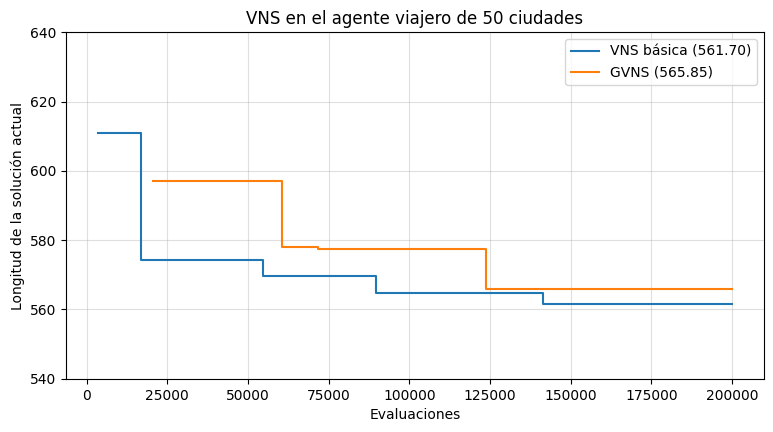

VNS básica: 48 agitaciones, longitud final 561.70
GVNS: 11 agitaciones, longitud final 565.85


In [9]:
random.seed(42)
np.random.seed(42)
_, c_basica, hist_basica = vns_basica(viajero, Presupuesto(200000), agitar_viajero)
random.seed(42)
np.random.seed(42)
_, c_gvns, hist_gvns = gvns(viajero, Presupuesto(200000), agitar_viajero, [DosOpt(viajero), OrOpt(viajero)])

plt.figure(figsize=(9, 4.5))
plt.step([h[0] for h in hist_basica], [h[1] for h in hist_basica], where='post', label=f'VNS básica ({c_basica:.2f})')
plt.step([h[0] for h in hist_gvns], [h[1] for h in hist_gvns], where='post', label=f'GVNS ({c_gvns:.2f})')
plt.xlabel('Evaluaciones')
plt.ylabel('Longitud de la solución actual')
plt.title('VNS en el agente viajero de 50 ciudades')
plt.ylim(540, 640)
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()
print(f"VNS básica: {len(hist_basica) - 1} agitaciones, longitud final {c_basica:.2f}")
print(f"GVNS: {len(hist_gvns) - 1} agitaciones, longitud final {c_gvns:.2f}")

La solución actual baja por escalones, porque solo cambia cuando la búsqueda que sigue a una agitación encuentra un óptimo local mejor. La VNS básica hace 48 agitaciones con el presupuesto y termina en 561,70. La GVNS hace solo 11, porque cada VND con or-opt cuesta muchas más evaluaciones que una búsqueda local con 2-opt, y termina en 565,85. En esta corrida, muchas agitaciones baratas rinden más que pocas búsquedas caras.

## Comparación

La celda siguiente compara la VNS básica y la GVNS con ILS y con la búsqueda tabú del capítulo 5, con 10 semillas y los presupuestos del capítulo 5, 100 000 evaluaciones en la mochila de 100 objetos y 200 000 en el agente viajero. La GVNS usa *flip*, intercambio 1-1 e intercambio 1-2 en la mochila, y 2-opt y or-opt en el agente viajero.

In [10]:
metodos = {
    'VNS básica': lambda prob, pres, ag, vecs, muestra: vns_basica(prob, pres, ag)[:2],
    'GVNS': lambda prob, pres, ag, vecs, muestra: gvns(prob, pres, ag, vecs)[:2],
    'ILS': lambda prob, pres, ag, vecs, muestra: busqueda_local_iterada(prob, pres),
    'Tabú': lambda prob, pres, ag, vecs, muestra: busqueda_tabu(prob, pres, permanencia=20, muestra=muestra)[:2],
}
problemas = {
    'Mochila (100 objetos)': (mochila100, 100000, agitar_mochila,
                              [Flip(mochila100), Intercambio(mochila100), Intercambio12(mochila100)], 200),
    'Viajero (50 ciudades)': (viajero, 200000, agitar_viajero, [DosOpt(viajero), OrOpt(viajero)], None),
}
num_semillas = 10
resultados = {}
for nombre_prob, (prob, max_eval, ag, vecs, muestra) in problemas.items():
    for nombre_met, metodo in metodos.items():
        inicio = time.perf_counter()
        costos = []
        for semilla in range(num_semillas):
            random.seed(semilla)
            np.random.seed(semilla)
            costos.append(metodo(prob, Presupuesto(max_eval), ag, vecs, muestra)[1])
        resultados[(nombre_prob, nombre_met)] = (costos, time.perf_counter() - inicio)

for nombre_prob, (prob, max_eval, *_ ) in problemas.items():
    signo = -1 if nombre_prob.startswith('Mochila') else 1
    print(f"{nombre_prob}, presupuesto de {max_eval:,d} evaluaciones, {num_semillas} semillas")
    print(f"  {'método':<10} | {'promedio':>9} | {'mejor':>8} | {'peor':>8} | {'tiempo':>7}")
    for nombre_met in metodos:
        costos, t = resultados[(nombre_prob, nombre_met)]
        v = [signo * c for c in costos]
        mejor, peor = (max(v), min(v)) if signo < 0 else (min(v), max(v))
        print(f"  {nombre_met:<10} | {np.mean(v):>9.2f} | {mejor:>8.2f} | {peor:>8.2f} | {t:>6.1f}s")
    print()
for nombre_met in metodos:
    costos = resultados[('Mochila (100 objetos)', nombre_met)][0]
    print(f"{nombre_met:<10}: óptimo de la mochila en {sum(-c == OPTIMO_MOCHILA100 for c in costos)} de {num_semillas} semillas")

Mochila (100 objetos), presupuesto de 100,000 evaluaciones, 10 semillas
  método     |  promedio |    mejor |     peor |  tiempo
  VNS básica |   3023.00 |  3054.00 |  2984.00 |    2.3s
  GVNS       |   3196.00 |  3204.00 |  3194.00 |    3.3s
  ILS        |   3023.00 |  3064.00 |  2984.00 |    2.3s
  Tabú       |   3016.00 |  3044.00 |  2984.00 |    3.8s

Viajero (50 ciudades), presupuesto de 200,000 evaluaciones, 10 semillas
  método     |  promedio |    mejor |     peor |  tiempo
  VNS básica |    561.70 |   556.20 |   576.84 |    4.1s
  GVNS       |    562.41 |   556.84 |   570.48 |    3.0s
  ILS        |    559.06 |   556.20 |   566.77 |    3.4s
  Tabú       |    567.56 |   556.20 |   586.44 |    2.8s

VNS básica: óptimo de la mochila en 0 de 10 semillas
GVNS      : óptimo de la mochila en 2 de 10 semillas
ILS       : óptimo de la mochila en 0 de 10 semillas
Tabú      : óptimo de la mochila en 0 de 10 semillas


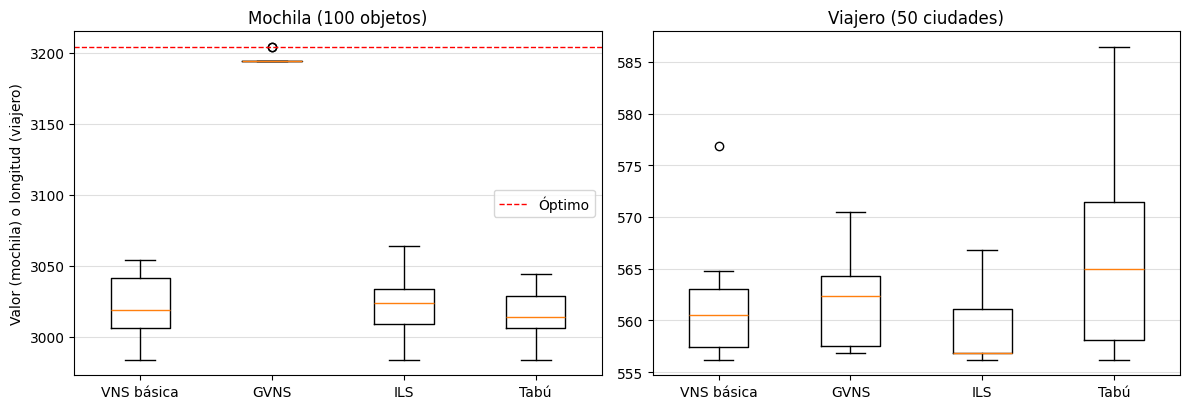

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for eje, nombre_prob in zip(ejes, problemas):
    signo = -1 if nombre_prob.startswith('Mochila') else 1
    eje.boxplot([[signo * c for c in resultados[(nombre_prob, m)][0]] for m in metodos])
    eje.set_xticks(range(1, len(metodos) + 1))
    eje.set_xticklabels(list(metodos))
    eje.set_title(nombre_prob)
    eje.grid(True, axis='y', alpha=0.4)
ejes[0].axhline(OPTIMO_MOCHILA100, color='red', linestyle='--', linewidth=1, label='Óptimo')
ejes[0].legend()
ejes[0].set_ylabel('Valor (mochila) o longitud (viajero)')
plt.tight_layout()
plt.show()

En la mochila, la GVNS es el único de los cuatro métodos que llega cerca del óptimo. Su promedio es 3196, y alcanza el óptimo de 3204 en 2 de las 10 semillas. La VNS básica queda en 3023, como ILS, porque su búsqueda local usa los mismos vecindarios que ILS y ninguna agitación de unos pocos cambios de estado reemplaza al intercambio 1-2. Como el VND con intercambio 1-2 gasta casi todo el presupuesto en su primer descenso, la GVNS hace pocas agitaciones y su resultado es casi el de un solo VND. En el capítulo 5, GRASP llegó al óptimo en todas las semillas por otra vía, construyendo soluciones con muchos objetos livianos.

En el agente viajero, los cuatro métodos quedan cerca. ILS tiene el menor promedio, 559,06, seguido de la VNS básica, con 561,70, la GVNS, con 562,41, y la búsqueda tabú, con 567,56. La VNS básica se parece mucho a ILS, porque las dos repiten perturbación y búsqueda local. La VNS agrega el tamaño variable de la agitación y solo acepta soluciones mejores, mientras que ILS acepta también soluciones iguales. Con 10 semillas, estas diferencias no permiten ordenar los métodos; el capítulo 16 trata cómo hacerlo.